Number of Customers: 20
Vehicle Capacity: 15
Customer Demands: [4 4 1 2 4 5 3 5 5 2 5 2 2 4 4 1 5 1 5 1]

========== ACO VEHICLE ROUTING RESULT ==========

Vehicle 1:
Route: 0 -> 10 -> 12 -> 16 -> 4 -> 18 -> 14 -> 20 -> 3 -> 0
Total Load: 14/15

Vehicle 2:
Route: 0 -> 11 -> 6 -> 15 -> 0
Total Load: 14/15

Vehicle 3:
Route: 0 -> 7 -> 17 -> 8 -> 13 -> 0
Total Load: 15/15

Vehicle 4:
Route: 0 -> 19 -> 2 -> 5 -> 0
Total Load: 13/15

Vehicle 5:
Route: 0 -> 9 -> 1 -> 0
Total Load: 9/15

Total Distance: 727.63
Vehicles Used: 5

Execution Time: 483.1 ms

========== ACO RUNTIME ANALYSIS ==========

No. of Customers     ACO Runtime (ms)    
----------------------------------------
10                   29.40               
20                   74.60               
30                   74.50               
40                   108.39              
50                   179.39              
60                   341.73              
70                   306.56              
80                   382.7

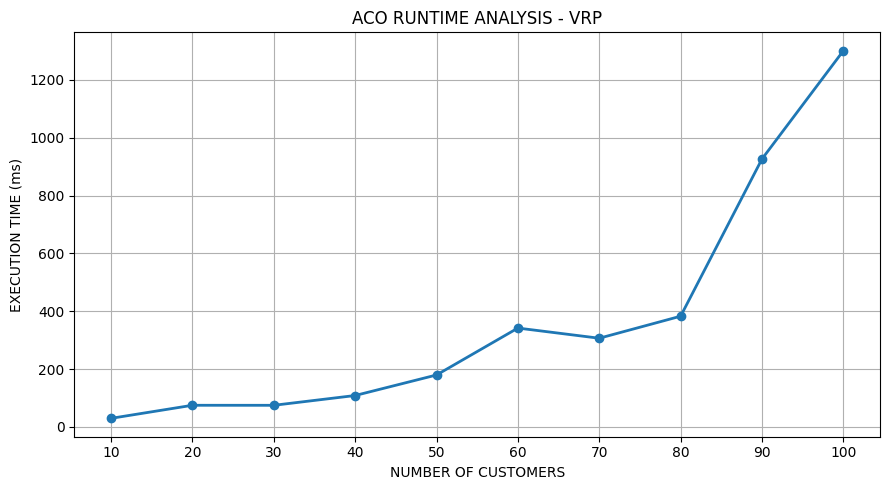

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ---------------------------------------------------------
# STEP 1: GENERATE VRP DATA
# ---------------------------------------------------------

def generate_vrp_data(n, seed=42):
    rng = np.random.default_rng(seed)

    # Node 0 is the depot; remaining nodes are customers
    coordinates = rng.uniform(0, 100, (n + 1, 2))

    # Customer demands (depot demand is zero)
    demands = np.zeros(n + 1, dtype=int)
    demands[1:] = rng.integers(1, 6, n)

    return coordinates, demands


# ---------------------------------------------------------
# STEP 2: CALCULATE DISTANCE MATRIX
# ---------------------------------------------------------

def calculate_distance_matrix(coordinates):
    n = len(coordinates)
    distance = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            distance[i][j] = np.linalg.norm(
                coordinates[i] - coordinates[j]
            )

    return distance


# ---------------------------------------------------------
# STEP 3: CALCULATE ROUTE DISTANCE
# ---------------------------------------------------------

def calculate_route_distance(routes, distance):
    total_distance = 0

    for route in routes:
        for i in range(len(route) - 1):
            total_distance += distance[route[i]][route[i + 1]]

    return total_distance


# ---------------------------------------------------------
# STEP 4: CONSTRUCT A SOLUTION USING AN ANT
# ---------------------------------------------------------

def construct_solution(distance, demands, capacity,
                       pheromone, alpha, beta, rng):

    n = len(demands) - 1
    unvisited = set(range(1, n + 1))
    routes = []

    while unvisited:
        current = 0
        remaining_capacity = capacity
        route = [0]

        while True:

            # Find customers that can be visited
            allowed = [
                customer for customer in unvisited
                if demands[customer] <= remaining_capacity
            ]

            if not allowed:
                break

            # Calculate transition probabilities
            probabilities = []

            for customer in allowed:
                tau = pheromone[current][customer]
                eta = 1 / (distance[current][customer] + 1e-10)

                probability = (tau ** alpha) * (eta ** beta)
                probabilities.append(probability)

            probabilities = np.array(probabilities)
            probabilities = probabilities / probabilities.sum()

            # Select the next customer probabilistically
            next_customer = rng.choice(
                allowed, p=probabilities
            )

            route.append(next_customer)
            unvisited.remove(next_customer)

            remaining_capacity -= demands[next_customer]
            current = next_customer

        # Return to depot
        route.append(0)
        routes.append(route)

    return routes


# ---------------------------------------------------------
# STEP 5: ANT COLONY OPTIMIZATION
# ---------------------------------------------------------

def run_aco(coordinates, demands, capacity,
            n_ants=10, iterations=30,
            alpha=1, beta=2, rho=0.5, Q=100,
            vehicle_penalty=20, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    distance = calculate_distance_matrix(coordinates)
    n = len(demands)

    # Initialize pheromone levels
    pheromone = np.ones((n, n))

    best_routes = None
    best_distance = float('inf')
    best_objective = float('inf')

    for iteration in range(iterations):

        ant_solutions = []

        # Each ant constructs a solution
        for ant in range(n_ants):

            routes = construct_solution(
                distance, demands, capacity,
                pheromone, alpha, beta, rng
            )

            total_distance = calculate_route_distance(
                routes, distance
            )

            # Objective considers distance and vehicles used
            objective = (
                total_distance + vehicle_penalty * len(routes)
            )

            ant_solutions.append(
                (routes, total_distance, objective)
            )

            if objective < best_objective:
                best_objective = objective
                best_routes = routes
                best_distance = total_distance

        # Select the best ant of this iteration
        iteration_best = min(
            ant_solutions, key=lambda x: x[2]
        )

        # Evaporate pheromone
        pheromone *= (1 - rho)

        # Only the best ant deposits pheromone
        routes, total_distance, objective = iteration_best

        deposit = Q / (objective + 1e-10)

        for route in routes:
            for i in range(len(route) - 1):
                a = route[i]
                b = route[i + 1]

                pheromone[a][b] += deposit
                pheromone[b][a] += deposit

    return best_routes, best_distance


# ---------------------------------------------------------
# STEP 6: DISPLAY TEXTUAL RESULTS
# ---------------------------------------------------------

def display_results(routes, distance, demands, capacity):

    print("\n========== ACO VEHICLE ROUTING RESULT ==========")

    for i, route in enumerate(routes):
        customers = route[1:-1]
        load = sum(demands[c] for c in customers)

        print(f"\nVehicle {i + 1}:")
        print("Route:", " -> ".join(map(str, route)))
        print(f"Total Load: {load}/{capacity}")

    print("\nTotal Distance:", round(distance, 2))
    print("Vehicles Used:", len(routes))
    print("================================================")


# ---------------------------------------------------------
# STEP 7: PERFORMANCE ANALYSIS
# ---------------------------------------------------------

def benchmark_aco():

    customer_counts = list(range(10, 101, 10))
    execution_times = []

    print("\n========== ACO RUNTIME ANALYSIS ==========")

    for n in customer_counts:

        coordinates, demands = generate_vrp_data(
            n, seed=100 + n
        )

        rng = np.random.default_rng(200 + n)

        start_time = time.perf_counter()

        run_aco(
            coordinates,
            demands,
            capacity=15,
            n_ants=5,
            iterations=8,
            alpha=1,
            beta=2,
            rho=0.5,
            Q=100,
            rng=rng
        )

        end_time = time.perf_counter()

        runtime = (end_time - start_time) * 1000
        execution_times.append(runtime)

    # Display performance table
    print("\n{:<20} {:<20}".format(
        "No. of Customers", "ACO Runtime (ms)"
    ))

    print("-" * 40)

    for n, runtime in zip(customer_counts, execution_times):
        print("{:<20} {:<20.2f}".format(n, runtime))

    # Plot runtime graph
    plt.figure(figsize=(9, 5))

    plt.plot(
        customer_counts,
        execution_times,
        marker='o',
        linewidth=2
    )

    plt.title("ACO RUNTIME ANALYSIS - VRP")
    plt.xlabel("NUMBER OF CUSTOMERS")
    plt.ylabel("EXECUTION TIME (ms)")

    plt.xticks(customer_counts)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# STEP 8: MAIN FUNCTION
# ---------------------------------------------------------

def main():

    # Problem parameters
    n_customers = 20
    vehicle_capacity = 15

    n_ants = 10
    iterations = 30

    alpha = 1
    beta = 2
    rho = 0.5
    Q = 100

    rng = np.random.default_rng(42)

    # Generate problem data
    coordinates, demands = generate_vrp_data(
        n_customers, seed=42
    )

    print("Number of Customers:", n_customers)
    print("Vehicle Capacity:", vehicle_capacity)
    print("Customer Demands:", demands[1:])

    # Execute ACO
    start_time = time.perf_counter()

    best_routes, best_distance = run_aco(
        coordinates,
        demands,
        vehicle_capacity,
        n_ants,
        iterations,
        alpha,
        beta,
        rho,
        Q,
        rng=rng
    )

    end_time = time.perf_counter()

    # Display final solution
    display_results(
        best_routes,
        best_distance,
        demands,
        vehicle_capacity
    )

    print(
        "\nExecution Time:",
        round((end_time - start_time) * 1000, 2),
        "ms"
    )

    # Generate performance table and graph
    benchmark_aco()


if __name__ == "__main__":
    main()